# Visual feature-space f_mem sanity study

This notebook uses saved CelebA images. It makes expected memorization behavior visible before it reports audit checks.

Set A contains training images. Set B contains held-out images. Nearest neighbors always come from A.

Quick results explain metric behavior. They are not paper estimates.

## Questions

1. How do interpolation and noise change d1, d2, r, and f_mem?
2. Does measured f_mem recover a known fraction of A copies?
3. Do SSCD, LPIPS, and DINOv2 select the same nearest images?
4. Does changing resolution change nearest-neighbor ratios?

## Metric language

For each query image, find its closest and second-closest images in A. Call these distances d1 and d2.

The ratio is r = d1 / d2. A ratio near zero means one A image is uniquely close.

f_mem is the fraction of query ratios below rho. Each feature space obtains rho from held-out images.

This notebook tests the measurement path. It does not estimate memorization in a trained generator.

In [42]:
# Purpose: Import the production metric APIs and locate this checkout.
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import json
import os
import sys

import matplotlib.pyplot as plt
import torch

REPO_ROOT = next(
    candidate
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (candidate / "mem_param_src").is_dir()
)
sys.path.insert(0, str(REPO_ROOT))

from mem_param_src.metrics import compute_nn_stats
from mem_param_src.metrics.image import (
    DINOv2FeatureEncoder, LPIPSFeatureEncoder, SSCDFeatureEncoder,
    compute_f_mem_reference_curve, encode_image_features,
)

print(f"repository: {REPO_ROOT}")
print(f"torch:      {torch.__version__}")
print(f"lpips:      {version('lpips')}")

repository: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_param_clean
torch:      2.5.1.post303
lpips:      0.1.4


## Settings

Use quick first. It uses small image banks and primary encoder resolutions.

Use full only inside an allocated GPU session. It uses larger banks and the resolution comparison.

In [62]:
# Purpose: Select one tested quick study or one researcher-run full study.
# Use the small CPU path by default. It avoids accidental GPU work.
PROFILE = "full"
DEVICE = "cuda"
RUN_RESOLUTION_CHECK = False
# Enable the optional resolution study only inside an allocated GPU session.
SEED = 2003
FEATURE_BATCH_SIZE = 32

PROFILES = {
    "quick": {
        "n_a": 32, "n_calibration": 128, "n_validation": 128,
        "n_b": 32, "n_pairs": 8, "n_query": 32,
        "alphas": [0.0, 0.25, 0.5, 0.75, 1.0],
        "sigmas": [0.0, 0.05, 0.10],
        "copy_fractions": [0.0, 0.25, 0.5, 0.75, 1.0],
    },
    "full": {
        "n_a": 256, "n_calibration": 1024, "n_validation": 1024,
        "n_b": 128, "n_pairs": 16, "n_query": 128,
        "alphas": [0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
        "sigmas": [0.0, 0.10, 0.20],
        "copy_fractions": [0.0, 0.125, 0.25, 0.5, 0.75, 0.875, 1.0],
    },
}
if PROFILE not in PROFILES:
    raise ValueError(f"Unknown PROFILE: {PROFILE}")
if PROFILE == "full" and DEVICE != "cuda":
    raise RuntimeError("Use DEVICE='cuda' for PROFILE='full'.")
if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested but no allocated GPU is visible.")

settings = PROFILES[PROFILE]
torch.manual_seed(SEED)
print(f"profile: {PROFILE}; device: {DEVICE}")
print(f"A/C/V/B: {settings['n_a']}/{settings['n_calibration']}/"
      f"{settings['n_validation']}/{settings['n_b']}")
print(f"pairs/query bank: {settings['n_pairs']}/{settings['n_query']}")

profile: full; device: cuda
A/C/V/B: 256/1024/1024/128
pairs/query bank: 16/128


## Load A, calibration, validation, and B

Keep these four groups disjoint. This gives each ratio threshold a held-out meaning.

All tensors use the saved minus-one to one image range.

In [63]:
# Purpose: Load exact saved images and create four fixed image groups.
# Load saved artifacts so this check never rebuilds or augments the dataset.
TRAIN_ARTIFACT = (REPO_ROOT / "outputs/job_sets/eps_recovery_1m/20260914T113123Z_2308577"
                  / "runs/1_eps_direct_full_heun_s0/data_bundle.pt")
VALID_ARTIFACT = (REPO_ROOT / "outputs/evals/eps_recovery_1m/20260915T111553Z_3025872_three_point"
                  / "reference/celeba32_valid_seed1_n10000.pt")
# Convert both artifacts to float tensors in the saved minus-one to one image range.
train_all = torch.load(TRAIN_ARTIFACT, map_location="cpu", weights_only=False)["train"].float()
valid_all = torch.load(VALID_ARTIFACT, map_location="cpu", weights_only=False)["reference"].float()

n_a = settings["n_a"]; n_calibration = settings["n_calibration"]
n_validation = settings["n_validation"]; n_b = settings["n_b"]
A = train_all[:n_a].contiguous()
calibration_images = valid_all[:n_calibration].contiguous()
validation_images = valid_all[n_calibration:n_calibration + n_validation].contiguous()
B = valid_all[n_calibration + n_validation:n_calibration + n_validation + n_b].contiguous()

print(f"A: {tuple(A.shape)}; calibration: {tuple(calibration_images.shape)}")
print(f"validation: {tuple(validation_images.shape)}; B: {tuple(B.shape)}")
print(f"range: [{float(A.min()):.3f}, {float(A.max()):.3f}]")

A: (256, 1, 32, 32); calibration: (1024, 1, 32, 32)
validation: (1024, 1, 32, 32); B: (128, 1, 32, 32)
range: [-1.000, 1.000]


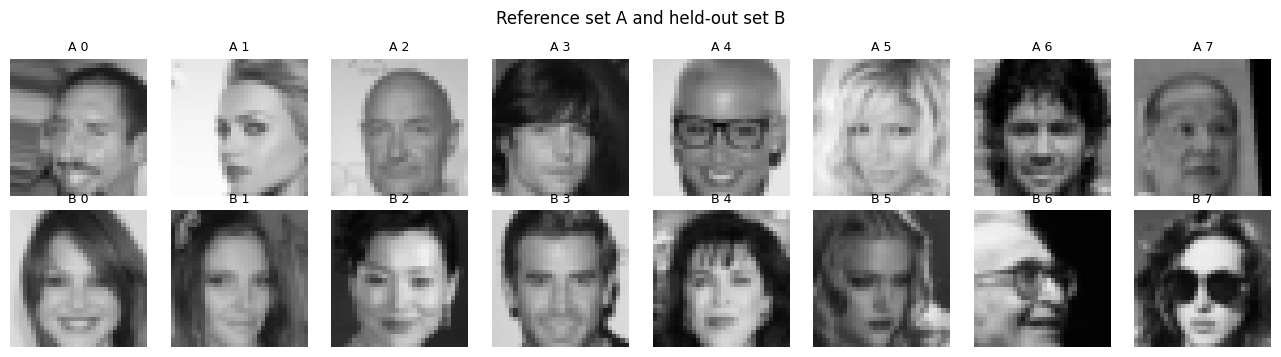

In [64]:
# Purpose: Show reference A and held-out B before metric calculations.
n_show = min(8, len(A), len(B))
fig, axes = plt.subplots(2, n_show, figsize=(13, 3.6))
for column in range(n_show):
    axes[0, column].imshow(A[column, 0].add(1).div(2), cmap="gray", vmin=0, vmax=1)
    axes[1, column].imshow(B[column, 0].add(1).div(2), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"A {column}", fontsize=9)
    axes[1, column].set_title(f"B {column}", fontsize=9)
for axis in axes.flat:
    axis.axis("off")
axes[0, 0].set_ylabel("train A", fontsize=10)
axes[1, 0].set_ylabel("held-out B", fontsize=10)
fig.suptitle("Reference set A and held-out set B")
plt.tight_layout(); plt.show()

## Build controlled queries

Interpolation controls distance from A to B. Noise controls corruption after interpolation.

The same noise direction is reused at each noise magnitude.

In [65]:
# Purpose: Build interpolation and known-copy images with fixed noise.
# Alpha moves one image pair from B toward A. Sigma adds the same noise direction.
alphas = settings["alphas"]; sigmas = settings["sigmas"]
copy_fractions = settings["copy_fractions"]; n_pairs = settings["n_pairs"]
n_query = settings["n_query"]; pair_A = A[:n_pairs]; pair_B = B[:n_pairs]
generator = torch.Generator().manual_seed(SEED)
pair_noise = torch.randn(pair_A.shape, generator=generator)

interpolation_blocks = []
for sigma in sigmas:
    for alpha in alphas:
        interpolation_blocks.append((alpha * pair_A + (1 - alpha) * pair_B + sigma * pair_noise).clamp(-1, 1))
interpolation_images = torch.cat(interpolation_blocks)

copy_source = A[torch.arange(n_query) % len(A)]
copy_noise = torch.randn(copy_source.shape, generator=generator)
copy_images = torch.cat([(copy_source + sigma * copy_noise).clamp(-1, 1) for sigma in sigmas])
B_query = B[:n_query]
print(f"interpolation images: {len(interpolation_images)}")
print(f"copy images: {len(copy_images)}; fractions: {copy_fractions}")

interpolation images: 288
copy images: 384; fractions: [0.0, 0.125, 0.25, 0.5, 0.75, 0.875, 1.0]


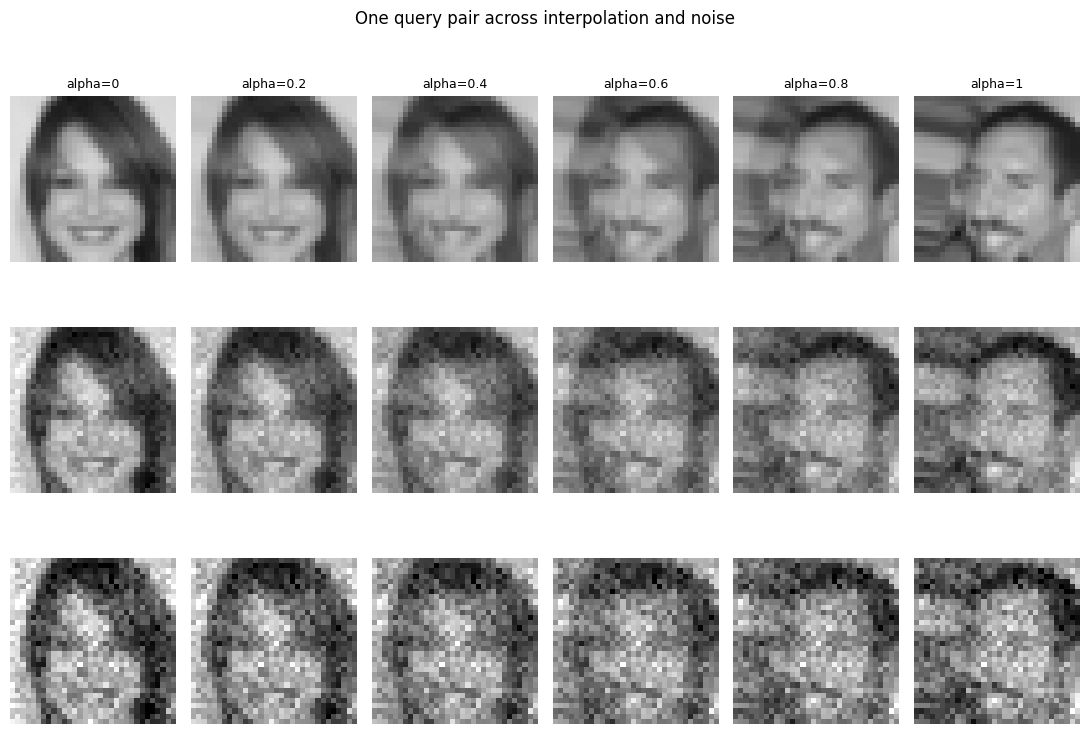

In [66]:
# Purpose: Show one A-to-B interpolation grid before feature extraction.
fig, axes = plt.subplots(len(sigmas), len(alphas), figsize=(11, 8))
for sigma_index, sigma in enumerate(sigmas):
    for alpha_index, alpha in enumerate(alphas):
        index = (sigma_index * len(alphas) + alpha_index) * n_pairs
        axes[sigma_index, alpha_index].imshow(interpolation_images[index, 0].add(1).div(2), cmap="gray", vmin=0, vmax=1)
        axes[sigma_index, alpha_index].axis("off")
        if sigma_index == 0: axes[sigma_index, alpha_index].set_title(f"alpha={alpha:g}", fontsize=9)
        if alpha_index == 0: axes[sigma_index, alpha_index].set_ylabel(f"sigma={sigma:g}", fontsize=9)
fig.suptitle("One query pair across interpolation and noise")
plt.tight_layout(); plt.show()

## Encode every source once

The feature pass uses the same source images for every later plot. It does not encode each query bank again.

In [67]:
# Purpose: Construct fixed production encoders from staged local assets.
ASSET_ROOT = REPO_ROOT / "outputs/model_assets/feature_f_mem"
with (ASSET_ROOT / "manifest.json").open() as handle: asset_manifest = json.load(handle)
asset_specs = asset_manifest["encoders"]
os.environ["TORCH_HOME"] = str(ASSET_ROOT / "torch_home")
encoders = {
    "SSCD": SSCDFeatureEncoder(ASSET_ROOT / asset_specs["sscd"]["path"], input_size=320),
    "LPIPS": LPIPSFeatureEncoder(input_size=32, weights_path=ASSET_ROOT / asset_specs["lpips_calibration"]["path"]),
    "DINOv2": DINOv2FeatureEncoder(ASSET_ROOT / asset_manifest["dinov2_source"]["path"], ASSET_ROOT / asset_specs["dinov2_weights"]["path"], input_size=224),
}
for space_name, encoder in encoders.items(): print(f"{space_name:7s} {encoder.name}")

/home/x_moalj/.conda/envs/mem_param_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/x_moalj/.conda/envs/mem_param_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/x_moalj/.conda/envs/mem_param_env/lib/python3.10/site-packages/lpips/lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code du

SSCD    sscd:disc_mixup:final_512:320
LPIPS   lpips:alex:v0.1:sqrt:32
DINOv2  dinov2:vits14:final_cls_l2:224


In [68]:
# Purpose: Encode all sources once and retain aligned feature blocks.
# Concatenation gives every encoder the same ordered images in one feature pass.
source_images = torch.cat([A, calibration_images, validation_images, B_query, interpolation_images, copy_images])
a_end = len(A); calibration_end = a_end + len(calibration_images)
validation_end = calibration_end + len(validation_images); b_end = validation_end + len(B_query)
interpolation_end = b_end + len(interpolation_images)
# These boundaries recover each source group from the shared feature matrix.
feature_sets = {}
for space_name, encoder in encoders.items():
    start = perf_counter()
    features = encode_image_features(source_images, encoder=encoder, batch_size=FEATURE_BATCH_SIZE, image_range="-1_1", device=DEVICE)
    feature_sets[space_name] = {
        "A": features[:a_end], "calibration": features[a_end:calibration_end],
        "validation": features[calibration_end:validation_end], "B": features[validation_end:b_end],
        "interpolation": features[b_end:interpolation_end],
        "copies": features[interpolation_end:].reshape(len(sigmas), n_query, -1),
    }
    print(f"{space_name:7s} {tuple(features.shape)} in {perf_counter() - start:.1f}s")

SSCD    (3104, 512) in 2.5s
LPIPS   (3104, 5760) in 0.2s
DINOv2  (3104, 384) in 2.9s


## Calibrate one threshold per feature space

The primary threshold is the 1% calibration ratio quantile. This threshold is fixed before controlled queries are measured.

In [69]:
# Purpose: Calculate held-out ratio distributions and separate rho values.
# Calibration sets rho. Validation checks its held-out false-positive rate.
quantiles = [0.001, 0.005, 0.01, 0.02, 0.05]
rho_by_space = {}; calibration_stats = {}; validation_stats = {}; curve_by_space = {}
for space_name, matrices in feature_sets.items():
    # Compare each held-out group only with A, the permitted neighbor set.
    calibration_stats[space_name] = compute_nn_stats(matrices["calibration"], matrices["A"])
    validation_stats[space_name] = compute_nn_stats(matrices["validation"], matrices["A"])
    curve_by_space[space_name] = compute_f_mem_reference_curve(validation_stats[space_name]["r"], calibration_stats[space_name]["r"], validation_stats[space_name]["r"], quantiles=quantiles)
    # Use the 1% calibration quantile as this feature space decision threshold.
    rho_by_space[space_name] = next(row["rho"] for row in curve_by_space[space_name] if row["heldout_quantile"] == 0.01)

print(f"{'space':8s} {'rho at 1%':>10s} {'validation rate':>17s}")
for space_name in feature_sets:
    row = next(row for row in curve_by_space[space_name] if row["heldout_quantile"] == 0.01)
    print(f"{space_name:8s} {row['rho']:10.4f} {row['validation_rate']:17.4f}")

space     rho at 1%   validation rate
SSCD         0.9164            0.0117
LPIPS        0.8001            0.0166
DINOv2       0.7847            0.0127


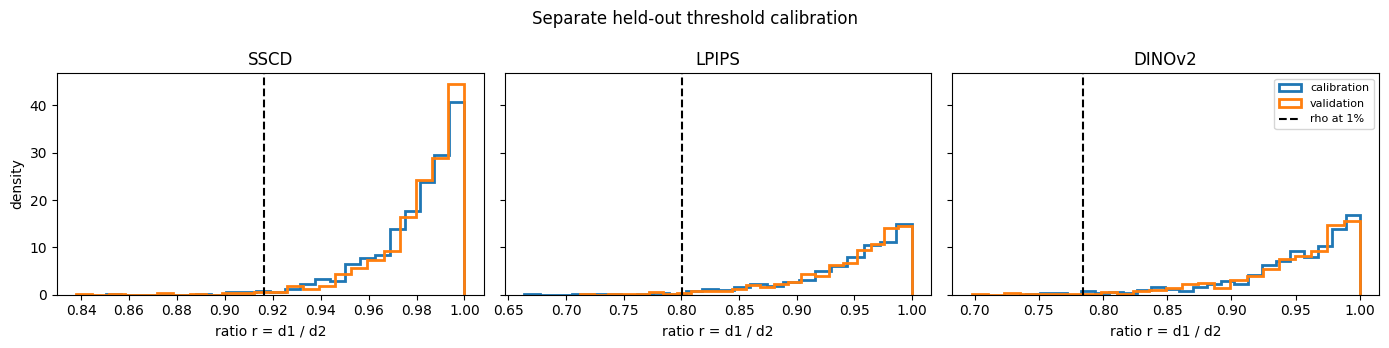

SSCD [(0.001, 0.8929), (0.005, 0.9083), (0.01, 0.9164), (0.02, 0.929), (0.05, 0.942)]
LPIPS [(0.001, 0.7117), (0.005, 0.7758), (0.01, 0.8001), (0.02, 0.8106), (0.05, 0.8431)]
DINOv2 [(0.001, 0.7543), (0.005, 0.7638), (0.01, 0.7847), (0.02, 0.8055), (0.05, 0.8416)]


In [70]:
# Purpose: Plot calibration and validation ratios with each primary rho.
fig, axes = plt.subplots(1, len(feature_sets), figsize=(14, 3.5), sharey=True)
for axis, space_name in zip(axes, feature_sets):
    axis.hist(calibration_stats[space_name]["r"].numpy(), bins=24, density=True, histtype="step", lw=2, label="calibration")
    axis.hist(validation_stats[space_name]["r"].numpy(), bins=24, density=True, histtype="step", lw=2, label="validation")
    axis.axvline(rho_by_space[space_name], color="black", ls="--", label="rho at 1%")
    axis.set_title(space_name); axis.set_xlabel("ratio r = d1 / d2")
axes[0].set_ylabel("density"); axes[-1].legend(fontsize=8)
fig.suptitle("Separate held-out threshold calibration")
plt.tight_layout(); plt.show()
for space_name, rows in curve_by_space.items(): print(space_name, [(row['heldout_quantile'], round(row['rho'], 4)) for row in rows])

## Interpolation and noise sweep

At alpha one and sigma zero, each query is an exact A copy. At alpha zero, each query is held-out B.

In [71]:
# Purpose: Calculate d1, d2, r, and f_mem across interpolation cells.
# One cell changes only alpha and noise, so every metric change has a known cause.
interpolation_metrics = {}
for space_name, matrices in feature_sets.items():
    values = {key: torch.zeros(len(sigmas), len(alphas)) for key in ["d1", "d2", "r", "f_mem"]}
    for sigma_index in range(len(sigmas)):
        for alpha_index in range(len(alphas)):
            start = (sigma_index * len(alphas) + alpha_index) * n_pairs
            # This slice contains n_pairs queries for one alpha and one noise level.
            stats = compute_nn_stats(matrices["interpolation"][start:start + n_pairs], matrices["A"])
            # Use medians for d1, d2, and r to limit one-query influence.
            values["d1"][sigma_index, alpha_index] = stats["d1"].median()
            values["d2"][sigma_index, alpha_index] = stats["d2"].median()
            values["r"][sigma_index, alpha_index] = stats["r"].median()
            # f_mem is the fraction of binary ratio decisions in this cell.
            values["f_mem"][sigma_index, alpha_index] = (stats["r"] < rho_by_space[space_name]).float().mean()
    interpolation_metrics[space_name] = values
for space_name, values in interpolation_metrics.items(): print(f"{space_name:7s} exact-copy f_mem={float(values['f_mem'][0, -1]):.3f}")

SSCD    exact-copy f_mem=1.000
LPIPS   exact-copy f_mem=1.000
DINOv2  exact-copy f_mem=1.000


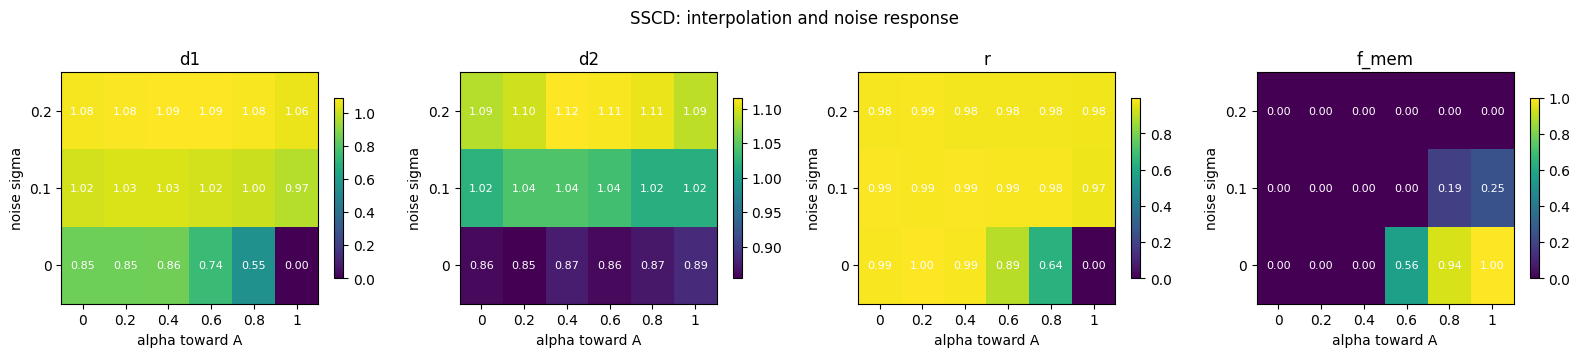

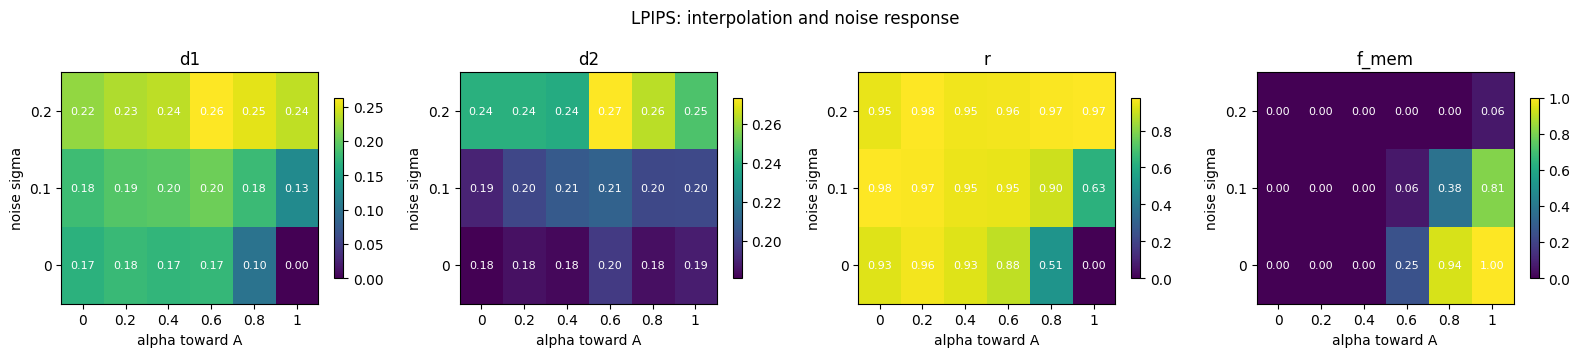

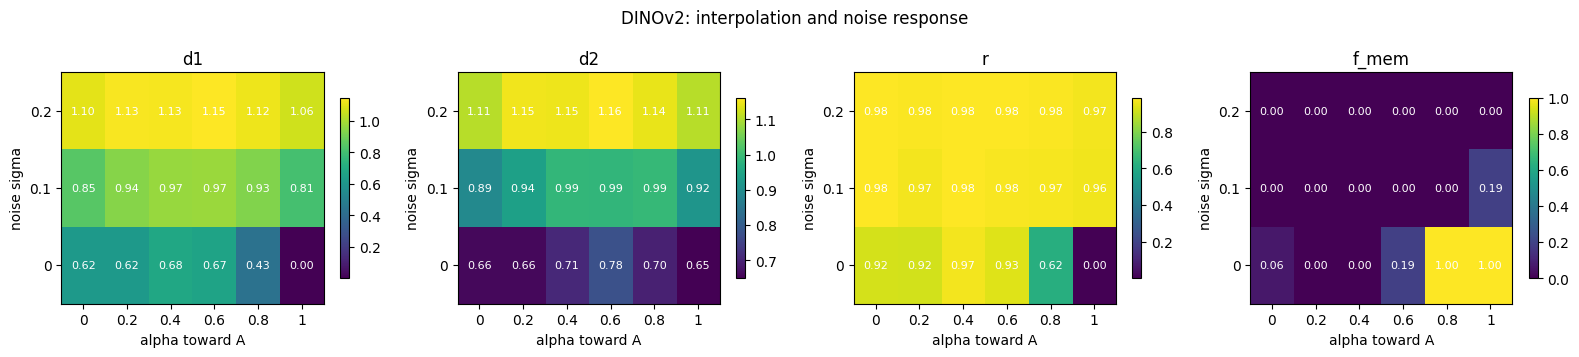

In [72]:
# Purpose: Plot visible metric surfaces for every learned feature space.
for space_name, values in interpolation_metrics.items():
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    for axis, key in zip(axes, ["d1", "d2", "r", "f_mem"]):
        image = axis.imshow(values[key].numpy(), aspect="auto", origin="lower", cmap="viridis")
        axis.set_title(key); axis.set_xticks(range(len(alphas)), [f"{alpha:g}" for alpha in alphas])
        axis.set_yticks(range(len(sigmas)), [f"{sigma:g}" for sigma in sigmas])
        axis.set_xlabel("alpha toward A"); axis.set_ylabel("noise sigma")
        for sigma_index in range(len(sigmas)):
            for alpha_index in range(len(alphas)):
                axis.text(alpha_index, sigma_index, f"{values[key][sigma_index, alpha_index]:.2f}", ha="center", va="center", color="white", fontsize=8)
        fig.colorbar(image, ax=axis, shrink=0.78)
    fig.suptitle(f"{space_name}: interpolation and noise response")
    plt.tight_layout(); plt.show()

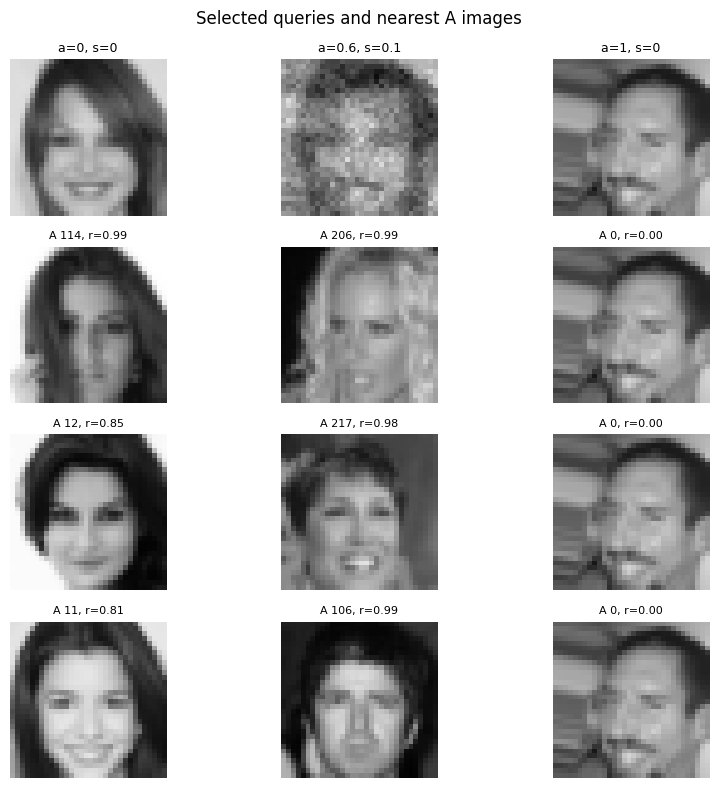

In [73]:
# Purpose: Show selected queries beside each space nearest training image.
selected = [(0, 0), (1, len(alphas) // 2), (0, len(alphas) - 1)]
fig, axes = plt.subplots(4, len(selected), figsize=(9, 8))
for column, (sigma_index, alpha_index) in enumerate(selected):
    index = (sigma_index * len(alphas) + alpha_index) * n_pairs
    axes[0, column].imshow(interpolation_images[index, 0].add(1).div(2), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"a={alphas[alpha_index]:g}, s={sigmas[sigma_index]:g}", fontsize=9)
    for row, space_name in enumerate(feature_sets, start=1):
        stats = compute_nn_stats(feature_sets[space_name]["interpolation"][index:index + 1], feature_sets[space_name]["A"])
        neighbor = int(stats["nn_idx"][0])
        axes[row, column].imshow(A[neighbor, 0].add(1).div(2), cmap="gray", vmin=0, vmax=1)
        axes[row, column].set_title(f"A {neighbor}, r={float(stats['r'][0]):.2f}", fontsize=8)
for row, label in enumerate(["query", *feature_sets.keys()]): axes[row, 0].set_ylabel(label, fontsize=10)
for axis in axes.flat: axis.axis("off")
fig.suptitle("Selected queries and nearest A images")
plt.tight_layout(); plt.show()

## Known copy-fraction experiment

Each bank replaces a known number of B images with noisy A copies. The horizontal axis is the true copy fraction.

In [74]:
# Purpose: Measure f_mem for query banks with known A-copy fractions.
copy_fraction_metrics = {}
for space_name, matrices in feature_sets.items():
    values = torch.zeros(len(sigmas), len(copy_fractions))
    for sigma_index in range(len(sigmas)):
        for fraction_index, copy_fraction in enumerate(copy_fractions):
            n_copy = round(copy_fraction * n_query)
            query_features = torch.cat([matrices["copies"][sigma_index, :n_copy], matrices["B"][:n_query - n_copy]])
            stats = compute_nn_stats(query_features, matrices["A"])
            values[sigma_index, fraction_index] = (stats["r"] < rho_by_space[space_name]).float().mean()
    copy_fraction_metrics[space_name] = values
for space_name, values in copy_fraction_metrics.items(): print(f"{space_name:7s} clean copy curve: {values[0].tolist()}")

SSCD    clean copy curve: [0.0078125, 0.1328125, 0.2578125, 0.5078125, 0.75, 0.875, 1.0]
LPIPS   clean copy curve: [0.0078125, 0.1328125, 0.2578125, 0.5078125, 0.75, 0.875, 1.0]
DINOv2  clean copy curve: [0.0078125, 0.1328125, 0.2578125, 0.5078125, 0.7578125, 0.8828125, 1.0]


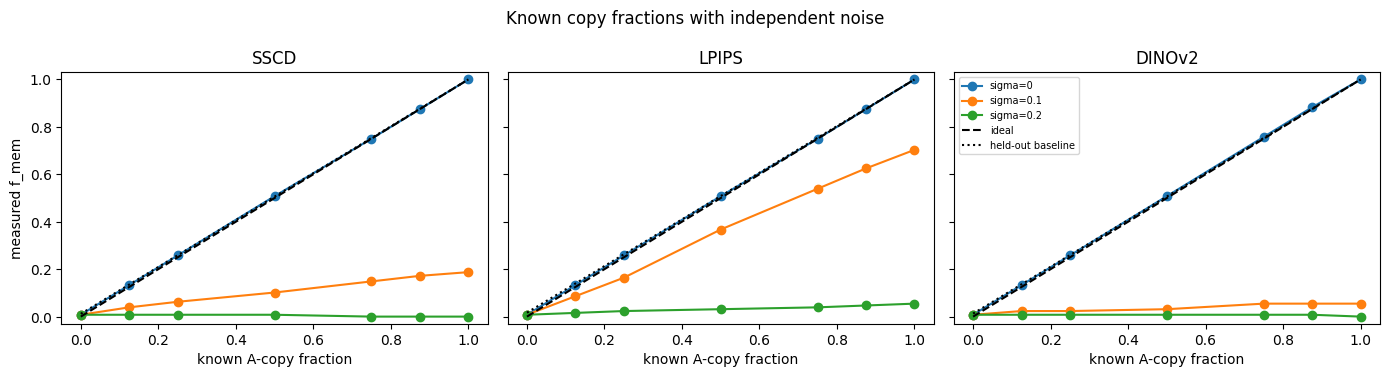

In [75]:
# Purpose: Compare measured f_mem with known copy fractions at each noise level.
fig, axes = plt.subplots(1, len(feature_sets), figsize=(14, 3.8), sharey=True)
for axis, space_name in zip(axes, feature_sets):
    validation_rate = next(row["validation_rate"] for row in curve_by_space[space_name] if row["heldout_quantile"] == 0.01)
    for sigma_index, sigma in enumerate(sigmas):
        axis.plot(copy_fractions, copy_fraction_metrics[space_name][sigma_index].numpy(), marker="o", label=f"sigma={sigma:g}")
    expected = [fraction + (1 - fraction) * validation_rate for fraction in copy_fractions]
    axis.plot(copy_fractions, copy_fractions, color="black", ls="--", label="ideal")
    axis.plot(copy_fractions, expected, color="black", ls=":", label="held-out baseline")
    axis.set_title(space_name); axis.set_xlabel("known A-copy fraction"); axis.set_ylim(-0.03, 1.03)
axes[0].set_ylabel("measured f_mem"); axes[-1].legend(fontsize=7, loc="upper left")
fig.suptitle("Known copy fractions with independent noise")
plt.tight_layout(); plt.show()

## Controlled A/B mixture proof

This test creates query banks with known contents. Each bank contains noisy A copies and held-out B images.

The A-copy fraction is known before measurement. The B images are never training images.

Mean r should decrease as the A-copy fraction increases. Mean f_mem should increase toward one.

The f_mem variance is the variance of the per-image binary decision. This is a path check, not a paper estimate.

In [76]:
# Purpose: Measure ratio and f_mem moments for known noisy A/B mixtures.
# A copies are known members because they come from the training set.
# B images are known non-members because they come from the held-out set.
mixture_metrics = {}
for space_name, matrices in feature_sets.items():
    # Store one scalar per noise level and known A-copy fraction.
    values = {
        key: torch.zeros(len(sigmas), len(copy_fractions))
        for key in ["mean_r", "var_r", "mean_f_mem", "var_f_mem"]
    }
    for sigma_index, sigma in enumerate(sigmas):
        for fraction_index, copy_fraction in enumerate(copy_fractions):
            # Replace this many B positions with A copies at one fixed noise level.
            n_copy = round(copy_fraction * n_query)
            query_features = torch.cat([
                matrices["copies"][sigma_index, :n_copy],
                matrices["B"][:n_query - n_copy],
            ])
            # r = d1 / d2. A small r means one A image is much nearer.
            stats = compute_nn_stats(query_features, matrices["A"])
            # This binary mask defines f_mem at the held-out calibrated rho.
            memorized = stats["r"] < rho_by_space[space_name]
            values["mean_r"][sigma_index, fraction_index] = stats["r"].mean()
            values["var_r"][sigma_index, fraction_index] = stats["r"].var(unbiased=False)
            values["mean_f_mem"][sigma_index, fraction_index] = memorized.float().mean()
            values["var_f_mem"][sigma_index, fraction_index] = memorized.float().var(unbiased=False)
    mixture_metrics[space_name] = values

# Check the clearest endpoints: B only versus exact A copies without noise.
for space_name, values in mixture_metrics.items():
    print(
        f"{space_name:7s} B-only: mean r={values['mean_r'][0, 0]:.3f}, "
        f"f_mem={values['mean_f_mem'][0, 0]:.3f}; "
        f"A-only: mean r={values['mean_r'][0, -1]:.3f}, "
        f"f_mem={values['mean_f_mem'][0, -1]:.3f}"
    )

SSCD    B-only: mean r=0.983, f_mem=0.008; A-only: mean r=0.000, f_mem=1.000
LPIPS   B-only: mean r=0.947, f_mem=0.008; A-only: mean r=0.000, f_mem=1.000
DINOv2  B-only: mean r=0.945, f_mem=0.008; A-only: mean r=0.000, f_mem=1.000


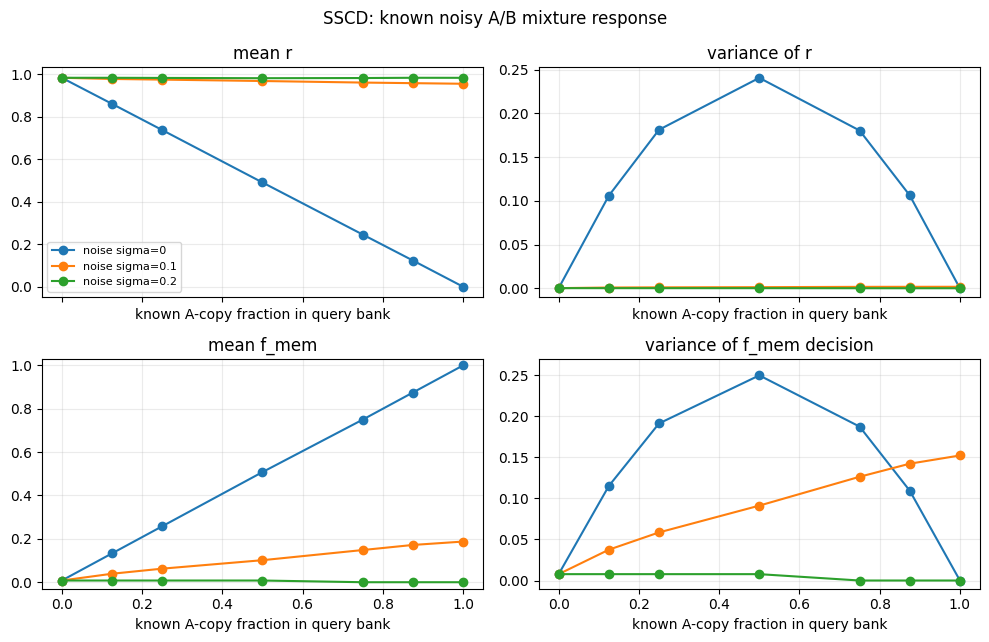

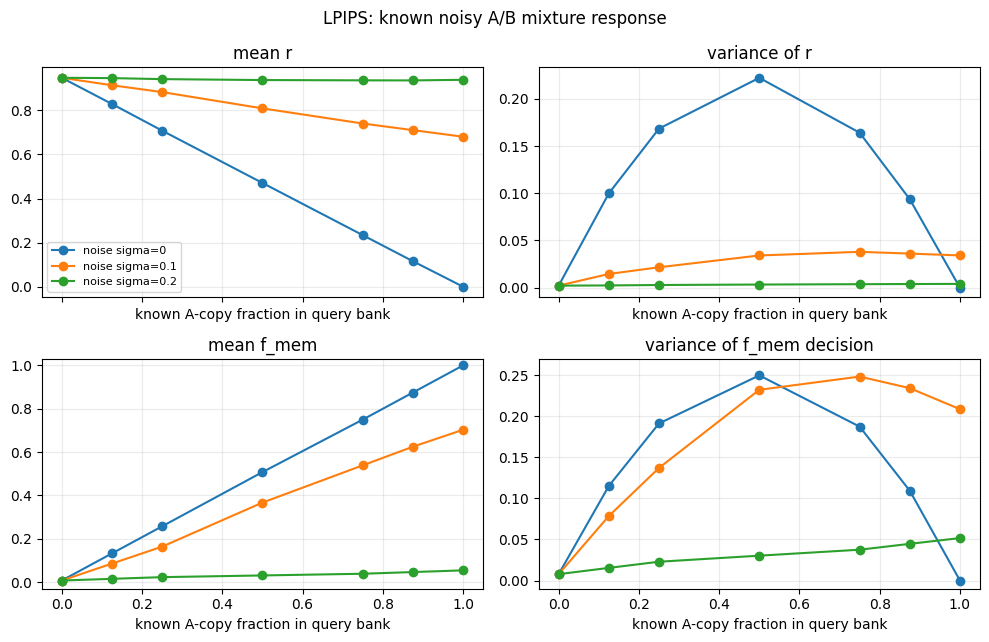

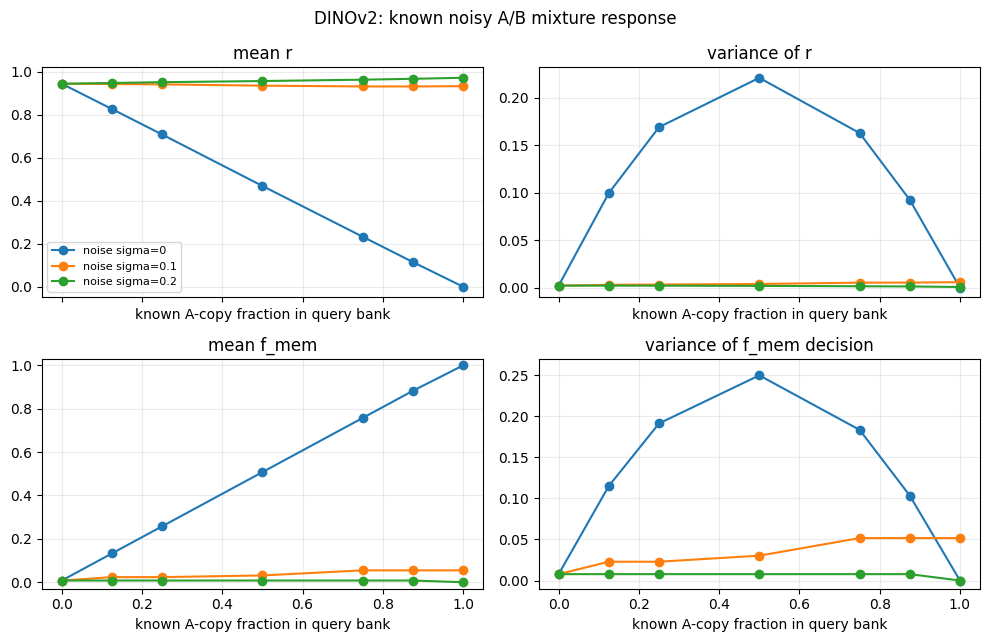

In [77]:
# Purpose: Plot the controlled A/B mixture moments for each feature extractor.
moment_labels = {
    "mean_r": "mean r",
    "var_r": "variance of r",
    "mean_f_mem": "mean f_mem",
    "var_f_mem": "variance of f_mem decision",
}
for space_name, values in mixture_metrics.items():
    # Use one panel per requested moment. Each line uses one fixed noise level.
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
    for axis, key in zip(axes.flat, moment_labels):
        for sigma_index, sigma in enumerate(sigmas):
            axis.plot(
                copy_fractions,
                values[key][sigma_index].numpy(),
                marker="o",
                label=f"noise sigma={sigma:g}",
            )
        axis.set_title(moment_labels[key])
        axis.set_xlabel("known A-copy fraction in query bank")
        axis.grid(alpha=0.25)
    # A binary decision has variance p(1-p), so it is largest near p=0.5.
    axes[0, 1].set_ylim(bottom=-0.01)
    axes[1, 0].set_ylim(-0.03, 1.03)
    axes[1, 1].set_ylim(-0.01, 0.27)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{space_name}: known noisy A/B mixture response")
    plt.tight_layout()
    plt.show()

## Optional resolution comparison

Run this section only for the full GPU profile. It compares ratios and nearest identities, not absolute distances.

In [78]:
# Purpose: Compare primary and alternate resolutions when the researcher enables this check.
if RUN_RESOLUTION_CHECK:
    alternate_sizes = {"SSCD": 288, "LPIPS": 64, "DINOv2": 518}
    fig, axes = plt.subplots(1, len(feature_sets), figsize=(14, 3.8))
    for axis, (space_name, encoder) in zip(axes, encoders.items()):
        primary_stats = compute_nn_stats(feature_sets[space_name]["interpolation"], feature_sets[space_name]["A"])
        original_size = encoder.input_size; encoder.input_size = alternate_sizes[space_name]
        try:
            alternate_A = encode_image_features(A, encoder=encoder, batch_size=FEATURE_BATCH_SIZE, image_range="-1_1", device=DEVICE)
            alternate_queries = encode_image_features(interpolation_images, encoder=encoder, batch_size=FEATURE_BATCH_SIZE, image_range="-1_1", device=DEVICE)
        finally:
            encoder.input_size = original_size
        alternate_stats = compute_nn_stats(alternate_queries, alternate_A)
        rank_primary = torch.argsort(torch.argsort(primary_stats["r"])).float()
        rank_alternate = torch.argsort(torch.argsort(alternate_stats["r"])).float()
        spearman = float(torch.corrcoef(torch.stack([rank_primary, rank_alternate]))[0, 1])
        agreement = float((primary_stats["nn_idx"] == alternate_stats["nn_idx"]).float().mean())
        axis.scatter(primary_stats["r"], alternate_stats["r"], s=12, alpha=0.7)
        limit = max(float(primary_stats["r"].max()), float(alternate_stats["r"].max()), 1e-6)
        axis.plot([0, limit], [0, limit], color="black", ls="--")
        axis.set_title(f"{space_name}: r_s={spearman:.3f}, NN={agreement:.3f}")
        axis.set_xlabel("primary r"); axis.set_ylabel("alternate r")
    fig.suptitle("Resolution sensitivity on interpolation queries")
    plt.tight_layout(); plt.show()
else:
    print("Set PROFILE='full', DEVICE='cuda', and RUN_RESOLUTION_CHECK=True to run this section.")

Set PROFILE='full', DEVICE='cuda', and RUN_RESOLUTION_CHECK=True to run this section.


## Compact implementation audit

This appendix checks implementation contracts after the visual study. It does not replace the figures.
The saved audit failure used the earlier 1e-5 batch-size tolerance. This cell has not run after the correction.


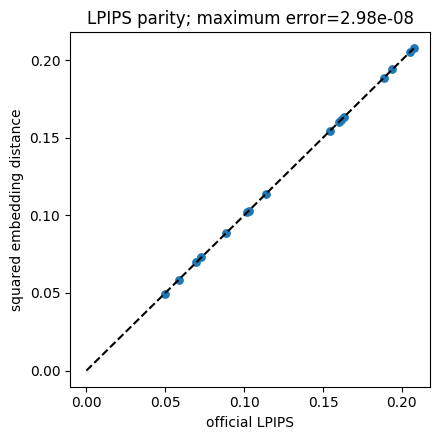

In [79]:
# Purpose: Plot official LPIPS scores against cached embedding distances.
lpips_encoder = encoders["LPIPS"]; lpips_device = next(lpips_encoder.model.parameters()).device
n_parity = min(16, len(A), len(B))
with torch.no_grad():
    package_scores = lpips_encoder.model(A[:n_parity].repeat(1, 3, 1, 1).to(lpips_device), B[:n_parity].repeat(1, 3, 1, 1).to(lpips_device)).flatten().cpu()
embedding_scores = (feature_sets["LPIPS"]["A"][:n_parity] - feature_sets["LPIPS"]["B"][:n_parity]).square().sum(dim=1)
max_lpips_error = float((package_scores - embedding_scores).abs().max())
limit = max(float(package_scores.max()), float(embedding_scores.max()), 1e-6)
plt.figure(figsize=(4.5, 4.5))
plt.scatter(package_scores, embedding_scores, s=28)
plt.plot([0, limit], [0, limit], color="black", ls="--")
plt.xlabel("official LPIPS"); plt.ylabel("squared embedding distance")
plt.title(f"LPIPS parity; maximum error={max_lpips_error:.2e}")
plt.tight_layout(); plt.show()

In [80]:
# Purpose: Report one compact audit after all visual results are available.
# Same-image GPU features can differ slightly across batch sizes.
# The 1e-4 tolerance is above the observed 6.16e-5 maximum and below a useful descriptor change.
repeat_tolerance = 1.0e-4
expected_dimensions = {"SSCD": 512, "LPIPS": 5760, "DINOv2": 384}
audit_ok = []
print(f"repeat tolerance: {repeat_tolerance:.1e}")
print(f"{'space':8s} {'dim':>6s} {'finite':>8s} {'repeat':>11s} {'copy d1':>10s} {'copy NN':>9s} {'mean norm':>11s}")
for space_name, encoder in encoders.items():
    # Change the batch size on purpose. This checks numerical batch stability.
    repeated = encode_image_features(A[:4], encoder=encoder, batch_size=4, image_range="-1_1", device=DEVICE)
    repeat_error = float((repeated - feature_sets[space_name]["A"][:4]).abs().max())
    # Alpha one and zero noise create an exact A[0] copy.
    exact_index = (len(alphas) - 1) * n_pairs
    exact_stats = compute_nn_stats(feature_sets[space_name]["interpolation"][exact_index:exact_index + 1], feature_sets[space_name]["A"])
    finite = bool(torch.isfinite(feature_sets[space_name]["A"]).all())
    dimension = int(feature_sets[space_name]["A"].shape[1])
    copy_d1 = float(exact_stats["d1"][0]); copy_index = int(exact_stats["nn_idx"][0])
    mean_norm = float(feature_sets[space_name]["A"].norm(dim=1).mean())
    audit_ok.append(finite and dimension == expected_dimensions[space_name] and repeat_error < repeat_tolerance and copy_d1 < 1e-3 and copy_index == 0)
    print(f"{space_name:8s} {dimension:6d} {str(finite):>8s} {repeat_error:11.2e} {copy_d1:10.2e} {copy_index:9d} {mean_norm:11.4f}")
audit_ok.append(max_lpips_error < 2e-5)
print(f"LPIPS parity maximum error: {max_lpips_error:.2e}")
if not all(audit_ok): raise RuntimeError("The feature-space audit did not pass.")
print("Audit passed. Review the figures before interpreting feature-space f_mem.")

repeat tolerance: 1.0e-04
space       dim   finite      repeat    copy d1   copy NN   mean norm
SSCD        512     True    6.03e-05   0.00e+00         0      1.0000
LPIPS      5760     True    6.16e-05   2.44e-04         0      0.6528
DINOv2      384     True    5.29e-07   6.91e-04         0      1.0000
LPIPS parity maximum error: 2.98e-08
Audit passed. Review the figures before interpreting feature-space f_mem.


## Researcher handoff

The executed quick profile checks code paths and visual logic. Do not report its values as experiment results.

For the larger GPU study, change these three settings: PROFILE equals full, DEVICE equals cuda, and RUN_RESOLUTION_CHECK equals True.

Run the notebook from an allocated GPU session. Inspect figures before starting the full three-seed evaluation.